# autoencoder_testing_v6

Run `autoencoder_training_v6.ipynb` first. Keep `autoencoder_v6_common.py` in this folder (and `autoencoder_v5_common.py` if you want the v5 comparison).

The v5 hold-out half of `known_test` (never used for tuning) is balanced 1:1 and scored with the saved v6 ensemble. v5 is scored on the **same** rows for a like-for-like comparison, including per-family recall.

## 1. Imports and paths

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Model
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score)
from autoencoder_v6_common import VERSION, SPLIT_TAG, FEATURES, validate_frame, transform, ensemble_base_scores, all_scores

PROJECT_ROOT = Path('..')
DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'Data_V2'
HOLDOUT_FILE = DATA_DIR / f'autoencoder_{SPLIT_TAG}_known_test_holdout.parquet'
MODEL_DIR = PROJECT_ROOT / 'saved-models' / f'autoencoder_{VERSION}'
RESULTS_DIR = PROJECT_ROOT / 'outputs' / 'results' / f'autoencoder_{VERSION}'
V5_MODEL_DIR = PROJECT_ROOT / 'saved-models' / 'autoencoder_v5'   # optional baseline
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
if not HOLDOUT_FILE.exists():
    raise FileNotFoundError(f'{HOLDOUT_FILE.resolve()} - run autoencoder_training_{VERSION}.ipynb first')

## 2. Load saved ensemble and balanced hold-out set

In [2]:
selection = json.loads((MODEL_DIR / f'autoencoder_{VERSION}_selection.json').read_text())
models = [tf.keras.models.load_model(MODEL_DIR / f) for f in selection['model_files']]
prep = joblib.load(MODEL_DIR / f'autoencoder_{VERSION}_preprocessing.joblib')
scales_list = joblib.load(MODEL_DIR / f'autoencoder_{VERSION}_residual_scales.joblib')
iforest = joblib.load(MODEL_DIR / f'autoencoder_{VERSION}_iforest.joblib')
refs = joblib.load(MODEL_DIR / f'autoencoder_{VERSION}_tail_refs.joblib')
if prep['features'] != FEATURES or models[0].input_shape[-1] != prep['input_dim']:
    raise ValueError('Training/test feature mismatch')

raw = pd.read_parquet(HOLDOUT_FILE).copy()
raw['Label'] = raw['Label'].astype(str).str.strip()
benign_df = raw.loc[raw['Label'].str.upper().eq('BENIGN')]
attack_df = raw.loc[~raw['Label'].str.upper().eq('BENIGN')]
if benign_df.empty or attack_df.empty: raise ValueError('Balanced testing requires both BENIGN and ATTACK samples')
n_per_class = min(len(benign_df), len(attack_df))
test_balanced = pd.concat([benign_df.sample(n=n_per_class, random_state=42, replace=False),
                           attack_df.sample(n=n_per_class, random_state=42, replace=False)],
                          ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)
print('Balanced hold-out -> BENIGN:', n_per_class, 'ATTACK:', n_per_class, 'TOTAL:', len(test_balanced))
test_df, X_test = validate_frame(test_balanced, 'holdout_balanced')
labels = test_df['Label'].astype(str).str.strip()
y_true = (~labels.str.upper().eq('BENIGN')).astype(int).to_numpy()
print('Test shape:', X_test.shape, '| Benign:', int((y_true == 0).sum()), 'Attacks:', int((y_true == 1).sum()))

Balanced hold-out -> BENIGN: 30895 ATTACK: 30895 TOTAL: 61790
Test shape: (61790, 69) | Benign: 30895 Attacks: 30895


## 3. Apply EXACT training preprocessing and score

In [3]:
X_scaled = transform(X_test, prep)
base = ensemble_base_scores(models, scales_list, X_scaled, 4096)
all_s, _ = all_scores(base, -iforest.score_samples(X_scaled), refs)   # refs come from benign validation
score_name = selection['score']; threshold = float(selection['threshold'])
errors = all_s[score_name]
y_pred = (errors > threshold).astype(int)
print('Port mode:', prep['port_mode'], '| Architecture:', selection['hidden'], selection['latent'], '| Seeds:', selection['seeds'],
      '| Score:', score_name, '| Target FPR:', selection['target_fpr'], '| Threshold:', threshold)

Port mode: engineered | Architecture: [48, 24] 12 | Seeds: [42, 43, 44] | Score: mse | Target FPR: 0.03 | Threshold: 0.05095853030681598


## 4. Evaluate on the untouched hold-out

In [4]:
def summarize(y_true, y_pred, s):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'accuracy': float((tp + tn) / (tp + tn + fp + fn)),
            'precision': float(precision_score(y_true, y_pred, zero_division=0)),
            'recall': float(recall_score(y_true, y_pred, zero_division=0)),
            'f1': float(f1_score(y_true, y_pred, zero_division=0)),
            'false_positive_rate': float(fp / (fp + tn)) if fp + tn else None,
            'false_negative_rate': float(fn / (fn + tp)) if fn + tp else None,
            'true_negative': int(tn), 'false_positive': int(fp), 'false_negative': int(fn), 'true_positive': int(tp),
            'roc_auc': float(roc_auc_score(y_true, s)), 'pr_auc': float(average_precision_score(y_true, s))}

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
metrics = summarize(y_true, y_pred, errors)
print(json.dumps(metrics, indent=2))
print(classification_report(y_true, y_pred, target_names=['BENIGN', 'ATTACK'], zero_division=0))
(RESULTS_DIR / f'autoencoder_{VERSION}_known_test_metrics.json').write_text(json.dumps(metrics, indent=2))

op_rows = []
for f, t in selection['thresholds'].items():
    m = summarize(y_true, (errors > t).astype(int), errors)
    op_rows.append({'target_fpr': float(f), 'threshold': t, 'recall': m['recall'], 'precision': m['precision'],
                    'f1': m['f1'], 'measured_fpr': m['false_positive_rate']})
op_table = pd.DataFrame(op_rows)
op_table.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_operating_points.csv', index=False)
display(op_table)

{
  "accuracy": 0.8428386470302638,
  "precision": 0.9592438432188692,
  "recall": 0.7161029292765819,
  "f1": 0.8200300227950852,
  "false_positive_rate": 0.03042563521605438,
  "false_negative_rate": 0.283897070723418,
  "true_negative": 29955,
  "false_positive": 940,
  "false_negative": 8771,
  "true_positive": 22124,
  "roc_auc": 0.9676484642853054,
  "pr_auc": 0.9660627931870744
}
              precision    recall  f1-score   support

      BENIGN       0.77      0.97      0.86     30895
      ATTACK       0.96      0.72      0.82     30895

    accuracy                           0.84     61790
   macro avg       0.87      0.84      0.84     61790
weighted avg       0.87      0.84      0.84     61790



,target_fpr,threshold,recall,precision,f1,measured_fpr
0,0.01,0.105728,0.571290,0.983232,0.722679,0.009743
1,0.03,0.050959,0.716103,0.959244,0.820030,0.030426
2,0.05,0.037157,0.768118,0.939693,0.845287,0.049296


## 5. Like-for-like comparison with v5 (optional)

Scores the saved v5 model on the same balanced hold-out rows with its own preprocessing, score and threshold.

In [5]:
summary_keys = ('recall', 'precision', 'f1', 'false_positive_rate', 'roc_auc', 'pr_auc')
comparison_rows = [{'model': f'autoencoder_{VERSION}', **{k: metrics[k] for k in summary_keys}}]
pred_v5 = None
try:
    import autoencoder_v5_common as v5c
    m5 = tf.keras.models.load_model(V5_MODEL_DIR / 'autoencoder_v5_model.keras')
    enc5 = Model(m5.input, m5.get_layer('bottleneck').output)
    p5 = joblib.load(V5_MODEL_DIR / 'autoencoder_v5_preprocessing.joblib')
    sc5 = joblib.load(V5_MODEL_DIR / 'autoencoder_v5_residual_scales.joblib')
    ls5 = joblib.load(V5_MODEL_DIR / 'autoencoder_v5_latent_stats.joblib')
    sel5 = json.loads((V5_MODEL_DIR / 'autoencoder_v5_selection.json').read_text())
    x5 = v5c.transform(X_test, p5)
    s5 = v5c.scores_by_method(x5, m5.predict(x5, batch_size=4096, verbose=0), sc5, enc5.predict(x5, batch_size=4096, verbose=0), ls5)[sel5['score']]
    pred_v5 = (s5 > float(sel5['threshold'])).astype(int)
    comparison_rows.insert(0, {'model': 'autoencoder_v5', **{k: v for k, v in summarize(y_true, pred_v5, s5).items() if k in summary_keys}})
except Exception as exc:
    print('v5 baseline skipped:', exc)
version_comparison = pd.DataFrame(comparison_rows)
version_comparison.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_vs_v5_comparison.csv', index=False)
display(version_comparison)

,model,precision,recall,f1,false_positive_rate,roc_auc,pr_auc
0,autoencoder_v5,0.960160,0.709079,0.815736,0.029422,0.967314,0.966543
1,autoencoder_v6,0.959244,0.716103,0.820030,0.030426,0.967648,0.966063


## 6. Attack-family report and diagnostics

,Samples,Detected,Mean_Score,Recall_v6,Recall_v5,Change
Label,,,,,,
Web Attack - SQL Injection,1,0,0.038378,0.000000,0.000000,0.000000
Web Attack - XSS,49,0,0.010630,0.000000,0.000000,0.000000
SSH-Patator,241,3,0.023641,0.012448,0.012448,0.000000
Web Attack - Brute Force,110,7,0.014664,0.063636,0.063636,0.000000
PortScan,6760,1203,0.033732,0.177959,0.021598,0.156361
Infiltration,3,2,0.131180,0.666667,0.333333,0.333333
DoS GoldenEye,771,546,0.153663,0.708171,0.722438,-0.014267
DDoS,9601,8188,0.270208,0.852828,0.944902,-0.092074
DoS Hulk,12954,11787,1.376227,0.909912,0.905666,0.004246


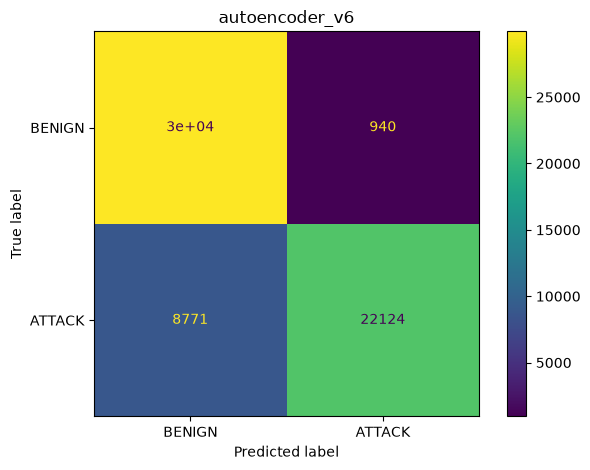

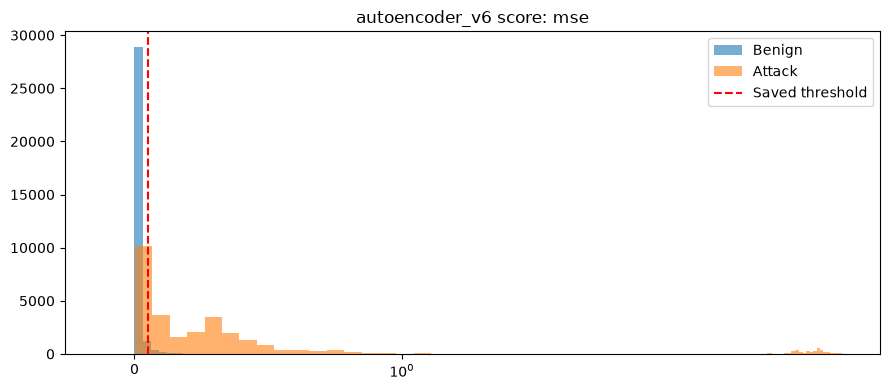

Final test metrics saved: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\autoencoder_v6


In [6]:
output = pd.DataFrame({'Label': labels, 'actual_attack': y_true, 'predicted_attack': y_pred, 'anomaly_score': errors})
if 'source_file' in test_df: output['source_file'] = test_df['source_file'].to_numpy()
output.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_known_test_predictions.csv', index=False)
attack = output.loc[output['actual_attack'] == 1].copy()
attack_report = attack.groupby('Label').agg(Samples=('predicted_attack', 'size'), Detected=('predicted_attack', 'sum'),
                                            Mean_Score=('anomaly_score', 'mean'))
attack_report[f'Recall_{VERSION}'] = attack_report['Detected'] / attack_report['Samples']
if pred_v5 is not None:
    v5_det = pd.Series(pred_v5[y_true == 1], index=attack.index).groupby(attack['Label']).mean()
    attack_report['Recall_v5'] = v5_det
    attack_report['Change'] = attack_report[f'Recall_{VERSION}'] - attack_report['Recall_v5']
attack_report = attack_report.sort_values(f'Recall_{VERSION}')
attack_report.to_csv(RESULTS_DIR / f'autoencoder_{VERSION}_attack_family_recall.csv')
display(attack_report)
ConfusionMatrixDisplay(cm, display_labels=['BENIGN', 'ATTACK']).plot()
plt.title(f'autoencoder_{VERSION}'); plt.tight_layout()
plt.savefig(RESULTS_DIR / f'autoencoder_{VERSION}_confusion_matrix.png', dpi=150); plt.show()
plt.figure(figsize=(9, 4)); plt.hist(errors[y_true == 0], bins=80, alpha=.6, label='Benign')
plt.hist(errors[y_true == 1], bins=80, alpha=.6, label='Attack')
plt.axvline(threshold, color='red', linestyle='--', label='Saved threshold')
plt.xscale('symlog'); plt.legend(); plt.title(f'autoencoder_{VERSION} score: {score_name}'); plt.tight_layout()
plt.savefig(RESULTS_DIR / f'autoencoder_{VERSION}_score_distribution.png', dpi=150); plt.show()
print('Final test metrics saved:', RESULTS_DIR.resolve())